In [1]:
from Model import RandomForest
from prepare_data import X_train, y_train, X_test, y_test
import matplotlib.pyplot as plt 

In [2]:
model = RandomForest(n_trees=1, max_depth=7, max_leaf_nodes=22, random_state=42)
model.fit(X_train, y_train)

In [3]:
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

In [4]:
Fault_types = [ 'BPFI',
                'BPFO',  
                'Misalign',
                'Normal',
                'Unbalance'
                ] 

In [5]:
import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score


def plot_multiclass_roc(model, X_test, y_test, Fault_types=None):
    """
    Plot ROC curves for multi-class classification using One-vs-Rest strategy

    Parameters
    ----------
    model : trained model
        Must implement predict_proba(X)
    X_test : array-like, shape (N, D)
        Test features
    y_test : array-like, shape (N,)
        True labels
    Fault_types : list of str, optional
        Names of classes (for legend)
    """

    # ===== Predict probabilities =====
    y_score = model.predict_proba(X_test)  # (N, C)
    n_classes = y_score.shape[1]

    # ===== Binarize labels =====
    y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

    # ===== Storage =====
    fpr = {}
    tpr = {}
    roc_auc = {}

    # ===== ROC per class =====
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # ===== Macro-average ROC =====
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

    mean_tpr /= n_classes

    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # ===== Plot =====
    plt.figure(figsize=(10, 6))

    plt.plot(
        fpr["macro"],
        tpr["macro"],
        linestyle="--",
        linewidth=3,
        label=f"Macro-average ROC (AUC = {roc_auc['macro']:.4f})"
    )

    for i in range(n_classes):
        label_name = f"Class {i}"
        if Fault_types is not None:
            label_name = Fault_types[i]

        plt.plot(
            fpr[i],
            tpr[i],
            linewidth=1.5,
            label=f"{label_name} (AUC = {roc_auc[i]:.4f})"
        )

    plt.plot([0, 1], [0, 1], "k--", linewidth=1)

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)

    plt.show()

    return roc_auc


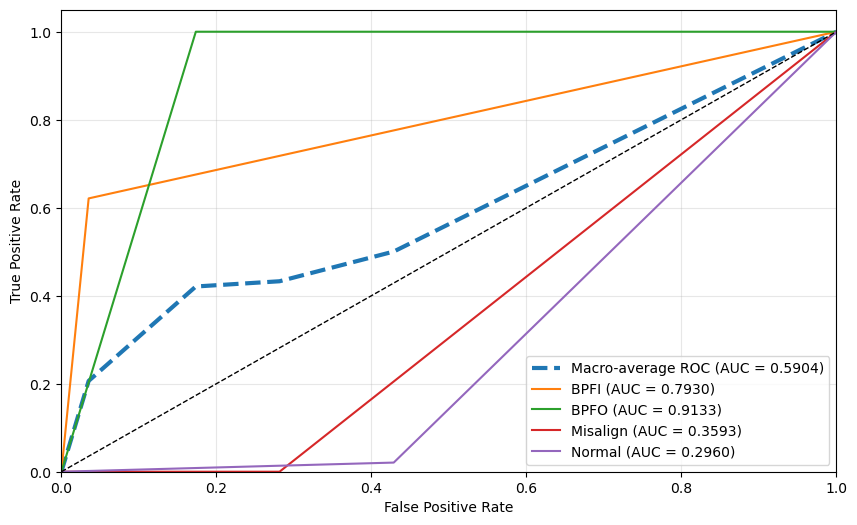

In [6]:
roc_auc = plot_multiclass_roc(
    model,
    X_test,
    y_test,
    Fault_types=Fault_types 
)


In [7]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score, precision_score
train_accuracy = accuracy_score(y_train, train_predict)
test_accuracy = accuracy_score(y_test, test_predict)

# --- Per-class metrics ---
# Recall per class
perclass_recall = recall_score(y_test, test_predict, average=None)
perclass_recall = [round(r, 4) for r in perclass_recall]

# Precision per class
perclass_precision = precision_score(y_test, test_predict, average=None, zero_division=0)
perclass_precision = [round(p, 4) for p in perclass_precision]

# F1 Score per class
perclass_f1 = f1_score(y_test, test_predict, average=None, zero_division=0)
perclass_f1 = [round(f, 4) for f in perclass_f1]

# Confusion Matrix
train_cm = confusion_matrix(y_train, train_predict)
test_cm = confusion_matrix(y_test, test_predict)

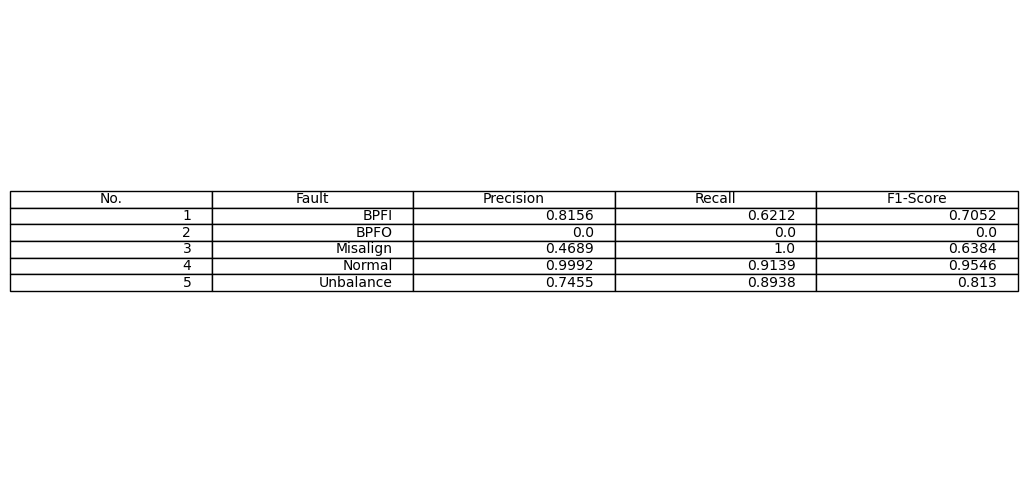

In [8]:
import pandas as pd
import matplotlib.pyplot as plt 
df_metrics = pd.DataFrame({
    "No.": range(1, len(Fault_types) + 1),
    "Fault": Fault_types,
    "Precision": perclass_precision,
    "Recall": perclass_recall,
    "F1-Score": perclass_f1,
})

# --- Plot table ---
fig, ax = plt.subplots(figsize=(13, 6))
ax.axis('tight')
ax.axis('off')
table = ax.table(cellText=df_metrics.values,
                 colLabels=df_metrics.columns,
                 loc='center')

plt.show()


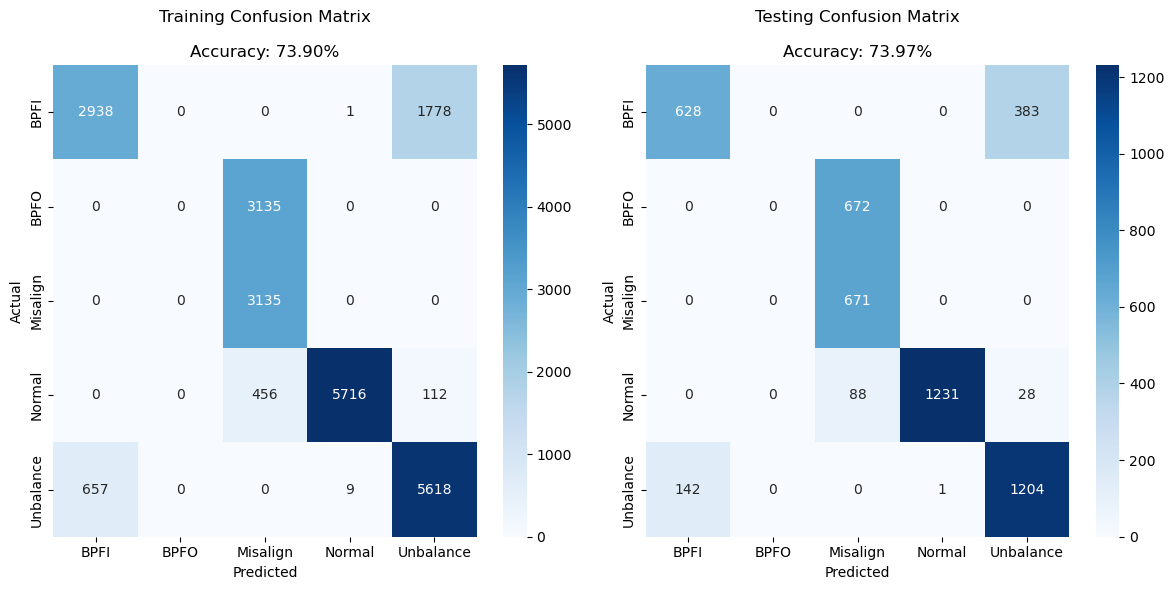

In [9]:
import seaborn as sns
#Biểu đồ confusion matrix
plt.figure(figsize=(12, 6))# Kích thước biểu đồ
plt.subplot(1, 2, 1)# Vẽ biểu đồ đầu tiên trong 1 hàng 2 cột
sns.heatmap(train_cm, annot=True, fmt='d', cmap='Blues', 
xticklabels=Fault_types, yticklabels=Fault_types)# Vẽ heatmap với các nhãn trục x và y
plt.title(f'Training Confusion Matrix\n\nAccuracy: {train_accuracy*100:.2f}%' )# Tiêu đề biểu đồ
plt.xlabel('Predicted')# Nhãn trục x
plt.ylabel('Actual')# Nhãn trục y
plt.subplot(1, 2, 2)# Vẽ biểu đồ thứ hai trong 1 hàng 2 cột
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues',
xticklabels=Fault_types, yticklabels=Fault_types)# Vẽ heatmap với các nhãn trục x và y
plt.title(f'Testing Confusion Matrix\n\nAccuracy: {test_accuracy*100:.2f}%')# Tiêu đề biểu đồ
plt.xlabel('Predicted')# Nhãn trục x
plt.ylabel('Actual')# Nhãn trục y
plt.tight_layout()# Tự động điều chỉnh khoảng cách giữa các phần tử trong biểu đồ
plt.show()# Hiển thị biểu đồ


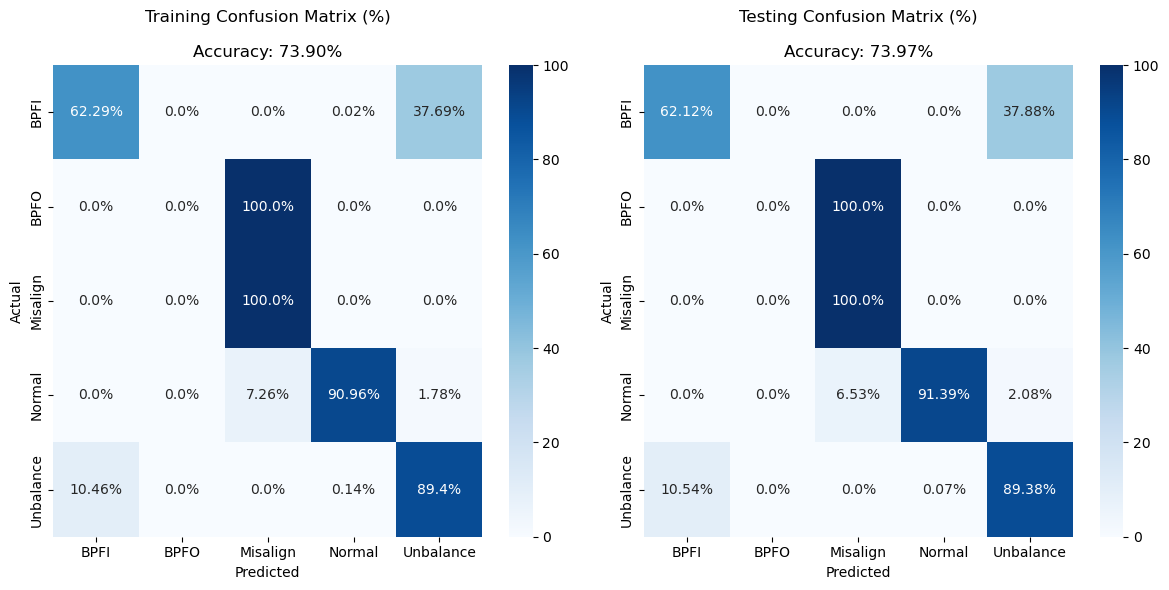

In [10]:
import numpy as np

# Chuẩn hóa theo hàng (Actual)
train_cm_percent = train_cm.astype('float') / train_cm.sum(axis=1, keepdims=True) * 100
test_cm_percent  = test_cm.astype('float') / test_cm.sum(axis=1, keepdims=True) * 100
import seaborn as sns
import matplotlib.pyplot as plt
annot_train = np.round(train_cm_percent, 2).astype(str) + '%'
annot_test  = np.round(test_cm_percent, 2).astype(str) + '%'

plt.figure(figsize=(12, 6))

# Training Confusion Matrix (%)
plt.subplot(1, 2, 1)
sns.heatmap(
    train_cm_percent,
    annot=annot_train,
    fmt='',
    cmap='Blues',
    xticklabels=Fault_types,
    yticklabels=Fault_types
)
plt.title(f'Training Confusion Matrix (%)\n\nAccuracy: {train_accuracy*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Testing Confusion Matrix (%)
plt.subplot(1, 2, 2)
sns.heatmap(
    test_cm_percent,
    annot=annot_test,
    fmt='',
    cmap='Blues',
    xticklabels=Fault_types,
    yticklabels=Fault_types
)
plt.title(f'Testing Confusion Matrix (%)\n\nAccuracy: {test_accuracy*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()
